<a href="https://colab.research.google.com/github/Mayurezh/Quantum-Classical-Hybrid-Model-for-Sentence-Similarity/blob/main/Quantum_Sentence_Similarity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1 — Install the libraries

In [1]:
%pip -q install -U sentence-transformers datasets pennylane scikit-learn scipy pandas numpy matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.


Step 2 — Verify the environment

In [2]:
import sys
import numpy as np
import pandas as pd
import torch
import pennylane as qml
import sklearn
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("Scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available; SBERT will use CPU.")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch: 2.14.1+cpu
PennyLane: 0.45.1
Scikit-learn: 1.9.1
CUDA available: False
GPU not available; SBERT will use CPU.


Step 3 — Load and inspect STS-B

We'll train on the official training split and evaluate model choices on the labelled validation split. The GLUE test labels may be unavailable or represented by placeholder values, so we won't assume they can be used for final scoring.

In [3]:
from datasets import load_dataset

# Using the full namespace/repository path to bypass the HfUriError
dataset = load_dataset("nyu-mll/glue", "stsb")

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

display(train_df[["sentence1", "sentence2", "label"]].head())

print("\nTraining score range:")
print(train_df["label"].describe())

print("\nValidation score range:")
print(val_df["label"].describe())

print("\nTest score range:")
print(test_df["label"].describe())

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

stsb/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  502kB            

stsb/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

stsb/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  151kB            

stsb/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

stsb/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  114kB            

... (3 outputs left out)

Generating test split:   0%|          | 0/1379 [00:00<?, ? examples/s]

Training rows: 5749
Validation rows: 1500
Test rows: 1379


,sentence1,sentence2,label
0,A plane is taking off.,An air plane is taking off.,5.00
1,A man is playing a large flute.,A man is playing a flute.,3.80
2,A man is spreading shreded cheese on a pizza.,A man is spreading shredded cheese on an uncoo...,3.80
3,Three men are playing chess.,Two men are playing chess.,2.60
4,A man is playing the cello.,A man seated is playing the cello.,4.25



Training score range:
count    5749.000000
mean        2.700999
std         1.464398
min         0.000000
25%         1.500000
50%         3.000000
75%         3.800000
max         5.000000
Name: label, dtype: float64

Validation score range:
count    1500.000000
mean        2.363908
std         1.500486
min         0.000000
25%         1.000000
50%         2.550000
75%         3.600000
max         5.000000
Name: label, dtype: float64

Test score range:
count    1379.0
mean       -1.0
std         0.0
min        -1.0
25%        -1.0
50%        -1.0
75%        -1.0
max        -1.0
Name: label, dtype: float64


Step 4 — Generate SBERT embeddings

This is the language-understanding component. Each sentence becomes a 384-dimensional vector.

In [4]:
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"

encoder = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=device
)

def encode_pairs(df, batch_size=32):
    sentences1 = df["sentence1"].astype(str).tolist()
    sentences2 = df["sentence2"].astype(str).tolist()

    emb1 = encoder.encode(
        sentences1,
        batch_size=batch_size,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    emb2 = encoder.encode(
        sentences2,
        batch_size=batch_size,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    return emb1.astype(np.float32), emb2.astype(np.float32)

X1_train, X2_train = encode_pairs(train_df)
X1_val, X2_val = encode_pairs(val_df)

y_train = train_df["label"].to_numpy(dtype=np.float32)
y_val = val_df["label"].to_numpy(dtype=np.float32)

print("Training embeddings:", X1_train.shape, X2_train.shape)
print("Validation embeddings:", X1_val.shape, X2_val.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (8 outputs left out)

Batches:   0%|          | 0/180 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Training embeddings: (5749, 384) (5749, 384)
Validation embeddings: (1500, 384) (1500, 384)


Step 5 — Build the classical baseline


First, compare sentence embeddings using cosine similarity. Because cosine similarity is not itself a 0–5 STS-B score, we fit a simple linear calibration on training data only.

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LinearRegression

cos_train = np.sum(X1_train * X2_train, axis=1) / (
    np.linalg.norm(X1_train, axis=1) *
    np.linalg.norm(X2_train, axis=1) + 1e-12
)

cos_val = np.sum(X1_val * X2_val, axis=1) / (
    np.linalg.norm(X1_val, axis=1) *
    np.linalg.norm(X2_val, axis=1) + 1e-12
)

cosine_calibrator = LinearRegression()
cosine_calibrator.fit(cos_train.reshape(-1, 1), y_train)

pred_cosine = cosine_calibrator.predict(cos_val.reshape(-1, 1))
pred_cosine = np.clip(pred_cosine, 0, 5)

print("Example predictions:", np.round(pred_cosine[:10], 2))
print("Actual scores:      ", y_val[:10])

Example predictions: [4.37 4.18 4.3  2.69 3.17 3.21 4.31 2.85 3.87 4.18]
Actual scores:       [5.    4.75  5.    2.4   2.75  2.615 5.    2.333 3.75  5.   ]


Step 6 — Train a stronger classical regression model

We use the absolute difference between each sentence's embeddings as pair features. This gives the quantum model a fairer comparison than cosine similarity alone.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Pair features: absolute embedding difference
X_train_pair = np.abs(X1_train - X2_train)
X_val_pair = np.abs(X1_val - X2_val)

pair_scaler = StandardScaler()
X_train_scaled = pair_scaler.fit_transform(X_train_pair)
X_val_scaled = pair_scaler.transform(X_val_pair)

classical_model = Ridge(alpha=10.0)
classical_model.fit(X_train_scaled, y_train)

pred_classical = np.clip(
    classical_model.predict(X_val_scaled), 0, 5
)

print("Classical regression predictions:", np.round(pred_classical[:10], 2))

Classical regression predictions: [5.   4.55 4.98 2.51 3.14 3.01 4.94 2.37 4.16 4.51]


Step 7 — Reduce the features for the quantum circuit

A four-qubit circuit accepts four angles in this experiment. PCA reduces the 384 pair features to four components. The scaler and PCA are fitted on training data only to avoid data leakage.

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

pca = PCA(n_components=4, random_state=SEED)

Z_train = pca.fit_transform(X_train_scaled)
Z_val = pca.transform(X_val_scaled)

# Map the four components to rotation angles in [-pi, pi]
angle_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))

angles_train = angle_scaler.fit_transform(Z_train)
angles_val = angle_scaler.transform(Z_val)

print("Reduced training shape:", Z_train.shape)
print("Reduced validation shape:", Z_val.shape)
print("Explained variance by 4 PCs:", pca.explained_variance_ratio_.sum())

Reduced training shape: (5749, 4)
Reduced validation shape: (1500, 4)
Explained variance by 4 PCs: 0.20288238


Step 8 — Define the quantum feature circuit

The circuit uses four qubits, rotation gates and a chain of CNOT gates. We measure the expectation value of Pauli-Z on each qubit to produce four quantum-derived features.

In [8]:
dev = qml.device("default.qubit", wires=4)

@qml.qnode(dev)
def quantum_circuit(angles):
    for i in range(4):
        qml.RY(angles[i], wires=i)

    qml.CNOT(wires=[0, 1])
    qml.CNOT(wires=[1, 2])
    qml.CNOT(wires=[2, 3])

    return tuple(
        qml.expval(qml.PauliZ(i))
        for i in range(4)
    )

def extract_quantum_features(angle_matrix):
    outputs = []

    for i, angles in enumerate(angle_matrix):
        result = quantum_circuit(angles)
        outputs.append(np.asarray(result, dtype=np.float32))

        if (i + 1) % 500 == 0:
            print(f"Processed {i + 1}/{len(angle_matrix)} pairs")

    return np.vstack(outputs)

# Test one circuit before processing the full dataset
print("Single circuit output:", quantum_circuit(angles_train[0]))

Single circuit output: (np.float64(-0.1761273187432879), np.float64(-0.12467429808116032), np.float64(-0.010647271714915973), np.float64(-0.00987276858378533))


Step 9 — Generate quantum features


This cell processes every training and validation pair through the circuit. It may take a little while; keep the Colab runtime connected.

In [9]:
Q_train = extract_quantum_features(angles_train)
Q_val = extract_quantum_features(angles_val)

print("Quantum training features:", Q_train.shape)
print("Quantum validation features:", Q_val.shape)

assert Q_train.shape == (len(train_df), 4)
assert Q_val.shape == (len(val_df), 4)
assert np.isfinite(Q_train).all()
assert np.isfinite(Q_val).all()

Processed 500/5749 pairs
Processed 1000/5749 pairs
Processed 1500/5749 pairs
Processed 2000/5749 pairs
Processed 2500/5749 pairs
Processed 3000/5749 pairs
Processed 3500/5749 pairs
Processed 4000/5749 pairs
Processed 4500/5749 pairs
Processed 5000/5749 pairs
Processed 5500/5749 pairs
Processed 500/1500 pairs
Processed 1000/1500 pairs
Processed 1500/1500 pairs
Quantum training features: (5749, 4)
Quantum validation features: (1500, 4)


Step 10 — Train the quantum and hybrid models

We'll compare PCA-based classical regression, quantum-only features, and the combined hybrid model.

In [10]:
# Classical regression on the four PCA components
pca_model = Ridge(alpha=10.0)
pca_model.fit(Z_train, y_train)

pred_pca = np.clip(pca_model.predict(Z_val), 0, 5)

# Regression using only quantum-derived features
quantum_scaler = StandardScaler()
Q_train_scaled = quantum_scaler.fit_transform(Q_train)
Q_val_scaled = quantum_scaler.transform(Q_val)

quantum_model = Ridge(alpha=10.0)
quantum_model.fit(Q_train_scaled, y_train)

pred_quantum = np.clip(
    quantum_model.predict(Q_val_scaled), 0, 5
)

# Hybrid model: four classical PCA features + four quantum features
H_train = np.concatenate([Z_train, Q_train_scaled], axis=1)
H_val = np.concatenate([Z_val, Q_val_scaled], axis=1)

hybrid_model = Ridge(alpha=10.0)
hybrid_model.fit(H_train, y_train)

pred_hybrid = np.clip(
    hybrid_model.predict(H_val), 0, 5
)

print("All three models trained.")
print("Hybrid feature dimensions:", H_train.shape[1])
print("Hybrid predictions:", np.round(pred_hybrid[:10], 2))

All three models trained.
Hybrid feature dimensions: 8
Hybrid predictions: [4.81 4.29 4.58 2.75 3.23 3.21 4.58 2.68 3.85 4.26]


Step 11 — Evaluate the models

Sentence similarity is a regression task, so our main metrics are Pearson correlation, Spearman correlation and mean squared error—not classification accuracy.

In [11]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate_model(name, actual, predicted):
    pearson = pearsonr(actual, predicted).statistic
    spearman = spearmanr(actual, predicted).statistic
    mse = mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mse)

    return {
        "Model": name,
        "Pearson": pearson,
        "Spearman": spearman,
        "MSE": mse,
        "MAE": mae,
        "RMSE": rmse
    }

results = pd.DataFrame([
    evaluate_model("SBERT + calibrated cosine", y_val, pred_cosine),
    evaluate_model("Classical Ridge (384 features)", y_val, pred_classical),
    evaluate_model("PCA + Ridge", y_val, pred_pca),
    evaluate_model("Quantum features + Ridge", y_val, pred_quantum),
    evaluate_model("Quantum-classical hybrid", y_val, pred_hybrid),
])

display(results.round(4))

,Model,Pearson,Spearman,MSE,MAE,RMSE
0,SBERT + calibrated cosine,0.8732,0.8670,0.5354,0.5682,0.7317
1,Classical Ridge (384 features),0.8523,0.8501,0.6169,0.6209,0.7855
2,PCA + Ridge,0.8652,0.8632,0.5676,0.5956,0.7534
3,Quantum features + Ridge,0.4678,0.4251,1.8750,1.1492,1.3693
4,Quantum-classical hybrid,0.8723,0.8639,0.5383,0.5703,0.7337


How to interpret the results:
- Higher Pearson and Spearman correlations generally indicate better agreement with human similarity judgments.
- Lower MSE, MAE and RMSE indicate smaller prediction errors.
- The hybrid model is useful only if it provides a measurable benefit over appropriate classical controls.

Step 12 — Visualize the results
Compare model performance

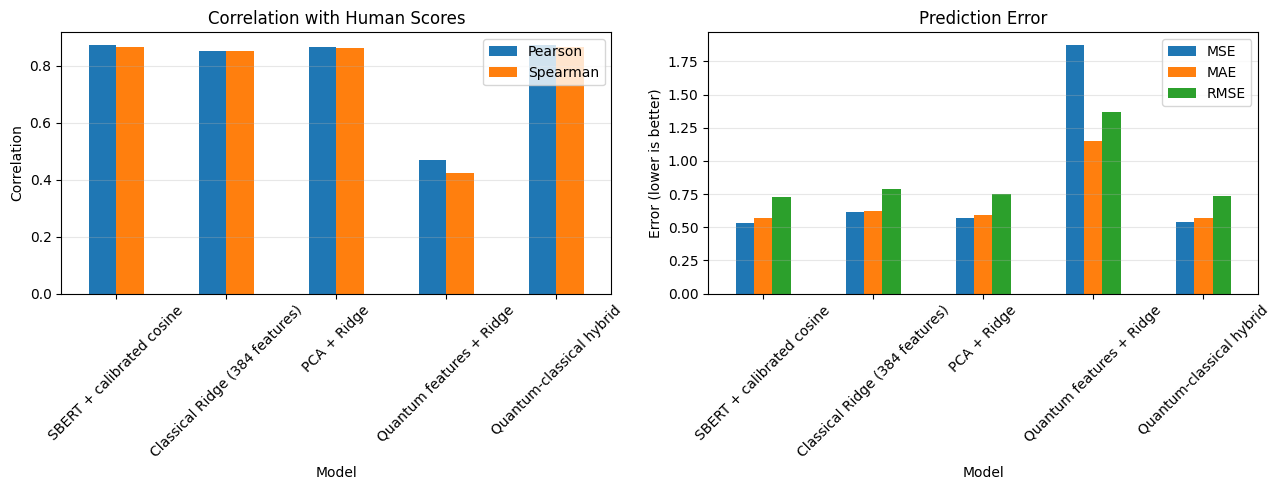

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

results.plot(
    x="Model", y=["Pearson", "Spearman"],
    kind="bar", ax=axes[0]
)
axes[0].set_title("Correlation with Human Scores")
axes[0].set_ylabel("Correlation")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", alpha=0.3)

results.plot(
    x="Model", y=["MSE", "MAE", "RMSE"],
    kind="bar", ax=axes[1]
)
axes[1].set_title("Prediction Error")
axes[1].set_ylabel("Error (lower is better)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Actual versus predicted scores

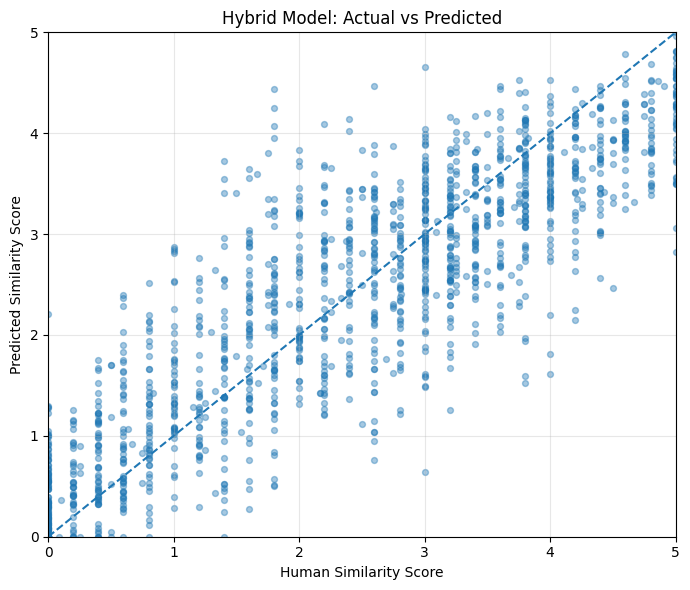

In [13]:
plt.figure(figsize=(7, 6))

plt.scatter(y_val, pred_hybrid, alpha=0.4, s=18)
plt.plot([0, 5], [0, 5], linestyle="--")

plt.xlabel("Human Similarity Score")
plt.ylabel("Predicted Similarity Score")
plt.title("Hybrid Model: Actual vs Predicted")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Points closer to the diagonal represent predictions closer to the human scores.

Step 13 — Save your research results

<Figure size 800x500 with 0 Axes>

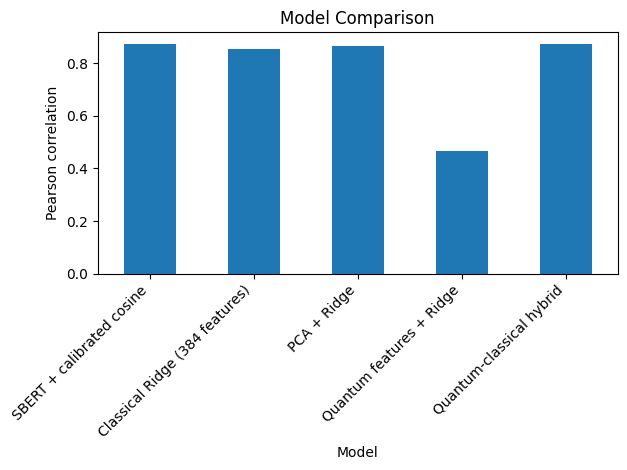

Saved results to: /content/quantum_sts_results
Files: ['pearson_comparison.png', 'validation_predictions.csv', 'model_comparison.csv']


In [14]:
from pathlib import Path

output_dir = Path("/content/quantum_sts_results")
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(output_dir / "model_comparison.csv", index=False)

# Save validation predictions for further analysis
predictions_df = pd.DataFrame({
    "sentence1": val_df["sentence1"],
    "sentence2": val_df["sentence2"],
    "human_score": y_val,
    "cosine_prediction": pred_cosine,
    "classical_prediction": pred_classical,
    "pca_prediction": pred_pca,
    "quantum_prediction": pred_quantum,
    "hybrid_prediction": pred_hybrid,
})

predictions_df.to_csv(
    output_dir / "validation_predictions.csv",
    index=False
)

plt.figure(figsize=(8, 5))
results.plot(
    x="Model", y="Pearson", kind="bar", legend=False
)
plt.ylabel("Pearson correlation")
plt.title("Model Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "pearson_comparison.png", dpi=200)
plt.show()

print("Saved results to:", output_dir)
print("Files:", [p.name for p in output_dir.iterdir()])

In [15]:
from google.colab import files

files.download("/content/quantum_sts_results/model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MODEL RESULTS VALUE

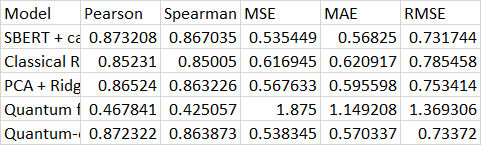

LIVE PREDICTION

In [16]:
def predict_similarity(sentence1, sentence2):
    # 1. Convert sentences into SBERT embeddings
    embeddings = encoder.encode(
        [sentence1, sentence2],
        convert_to_numpy=True,
        show_progress_bar=False
    )

    e1, e2 = embeddings[0], embeddings[1]

    # 2. Extract classical sentence-pair features
    pair_features = np.abs(e1 - e2).reshape(1, -1)
    pair_scaled = pair_scaler.transform(pair_features)

    # 3. Reduce features and encode them as quantum angles
    classical_features = pca.transform(pair_scaled)
    angles = angle_scaler.transform(classical_features)

    # 4. Extract quantum features
    q_features = np.asarray(
        quantum_circuit(angles[0]),
        dtype=np.float32
    ).reshape(1, -1)

    # 5. Combine classical and quantum features
    q_scaled = quantum_scaler.transform(q_features)
    hybrid_features = np.concatenate(
        [classical_features, q_scaled],
        axis=1
    )

    # 6. Predict similarity on the 0–5 scale
    score = float(hybrid_model.predict(hybrid_features)[0])
    score = float(np.clip(score, 0, 5))

    # 7. Display the result
    if score >= 4:
        interpretation = "Very high predicted similarity"
    elif score >= 3:
        interpretation = "High-to-moderate predicted similarity"
    elif score >= 2:
        interpretation = "Moderate predicted similarity"
    elif score >= 1:
        interpretation = "Low predicted similarity"
    else:
        interpretation = "Very low predicted similarity"

    print("=" * 50)
    print("SENTENCE SIMILARITY DEMO")
    print("=" * 50)
    print(f"Sentence 1: {sentence1}")
    print(f"Sentence 2: {sentence2}")
    print(f"\nPredicted score: {score:.2f} / 5.00")
    print(f"Interpretation: {interpretation}")
    print("=" * 50)

    return score

Example 1 · Similar meaning

In [17]:
predict_similarity(
    "The child is playing outside.",
    "A kid is playing outdoors."
)

SENTENCE SIMILARITY DEMO
Sentence 1: The child is playing outside.
Sentence 2: A kid is playing outdoors.

Predicted score: 4.29 / 5.00
Interpretation: Very high predicted similarity


4.285770893096924

Example 2 · Different meaning

In [18]:
predict_similarity("The weather is sunny today.", "The computer needs a new battery.")

SENTENCE SIMILARITY DEMO
Sentence 1: The weather is sunny today.
Sentence 2: The computer needs a new battery.

Predicted score: 0.05 / 5.00
Interpretation: Very low predicted similarity


0.051604270935058594

Example 3 · Related topic, different meaning

In [19]:
predict_similarity("A man is riding a bicycle.", "A man is repairing a bicycle.")

SENTENCE SIMILARITY DEMO
Sentence 1: A man is riding a bicycle.
Sentence 2: A man is repairing a bicycle.

Predicted score: 2.64 / 5.00
Interpretation: Moderate predicted similarity


2.6414315700531006

Example 4 · Paraphrase

In [20]:
predict_similarity("A man is riding a bicycle.", "A man is repairing a bicycle.")

SENTENCE SIMILARITY DEMO
Sentence 1: A man is riding a bicycle.
Sentence 2: A man is repairing a bicycle.

Predicted score: 2.64 / 5.00
Interpretation: Moderate predicted similarity


2.6414315700531006

In [21]:
display(results.round(4))

,Model,Pearson,Spearman,MSE,MAE,RMSE
0,SBERT + calibrated cosine,0.8732,0.8670,0.5354,0.5682,0.7317
1,Classical Ridge (384 features),0.8523,0.8501,0.6169,0.6209,0.7855
2,PCA + Ridge,0.8652,0.8632,0.5676,0.5956,0.7534
3,Quantum features + Ridge,0.4678,0.4251,1.8750,1.1492,1.3693
4,Quantum-classical hybrid,0.8723,0.8639,0.5383,0.5703,0.7337


In [22]:
predict_similarity("A man is riding a bicycle.", "A man is walking on road")

SENTENCE SIMILARITY DEMO
Sentence 1: A man is riding a bicycle.
Sentence 2: A man is walking on road

Predicted score: 1.23 / 5.00
Interpretation: Low predicted similarity


1.2272710800170898

In [23]:

import os
import pandas as pd

results_dir = "/content/quantum_sts_results"

if os.path.exists(results_dir):
    print("Found results directory:")
    for filename in os.listdir(results_dir):
        filepath = os.path.join(results_dir, filename)
        size_kb = os.path.getsize(filepath) / 1024
        print(f"{filename} — {size_kb:.1f} KB")

    csv_path = os.path.join(results_dir, "model_comparison.csv")

    if os.path.exists(csv_path):
        results = pd.read_csv(csv_path)
        display(results)
else:
    print("Results directory not found in this runtime.")
    print("Check Google Drive or your downloaded files.")


Found results directory:
pearson_comparison.png — 96.6 KB
validation_predictions.csv — 269.3 KB
model_comparison.csv — 0.6 KB


,Model,Pearson,Spearman,MSE,MAE,RMSE
0,SBERT + calibrated cosine,0.873208,0.867035,0.535449,0.568250,0.731744
1,Classical Ridge (384 features),0.852310,0.850050,0.616945,0.620917,0.785458
2,PCA + Ridge,0.865240,0.863226,0.567633,0.595598,0.753414
3,Quantum features + Ridge,0.467841,0.425057,1.875000,1.149208,1.369306
4,Quantum-classical hybrid,0.872322,0.863873,0.538345,0.570337,0.733720
